c:\Users\Natti\anaconda3\envs\ml_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Natti\.cache\kagglehub\datasets\sakshigoyal7\credit-card-customers\versions\1
Unknown in CLIENTNUM: 0 
Unknown in Attrition_Flag: 0 
Unknown in Customer_Age: 0 
Unknown in Gender: 0 
Unknown in Dependent_count: 0 
Unknown in Education_Level: 1519 
Unknown in Marital_Status: 749 
Unknown in Income_Category: 1112 
Unknown in Card_Category: 0 
Unknown in Months_on_book: 0 
Unknown in Total_Relationship_Count: 0 
Unknown in Months_Inactive_12_mon: 0 
Unknown in Contacts_Count_12_mon: 0 
Unknown in Credit_Limit: 0 
Unknown in Total_Revolving_Bal: 0 
Unknown in Avg_Open_To_Buy: 0 
Unknown in Total_Amt_Chng_Q4_Q1: 0 
Unknown in Total_Trans_Amt: 0 
Unknown in Total_Trans_Ct: 0 
Unknown in Total_Ct_Chng_Q4_Q1: 0 
Unknown in Avg_Utilization_Ratio: 0 
Unknown in Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1: 0 
Unknown in Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts

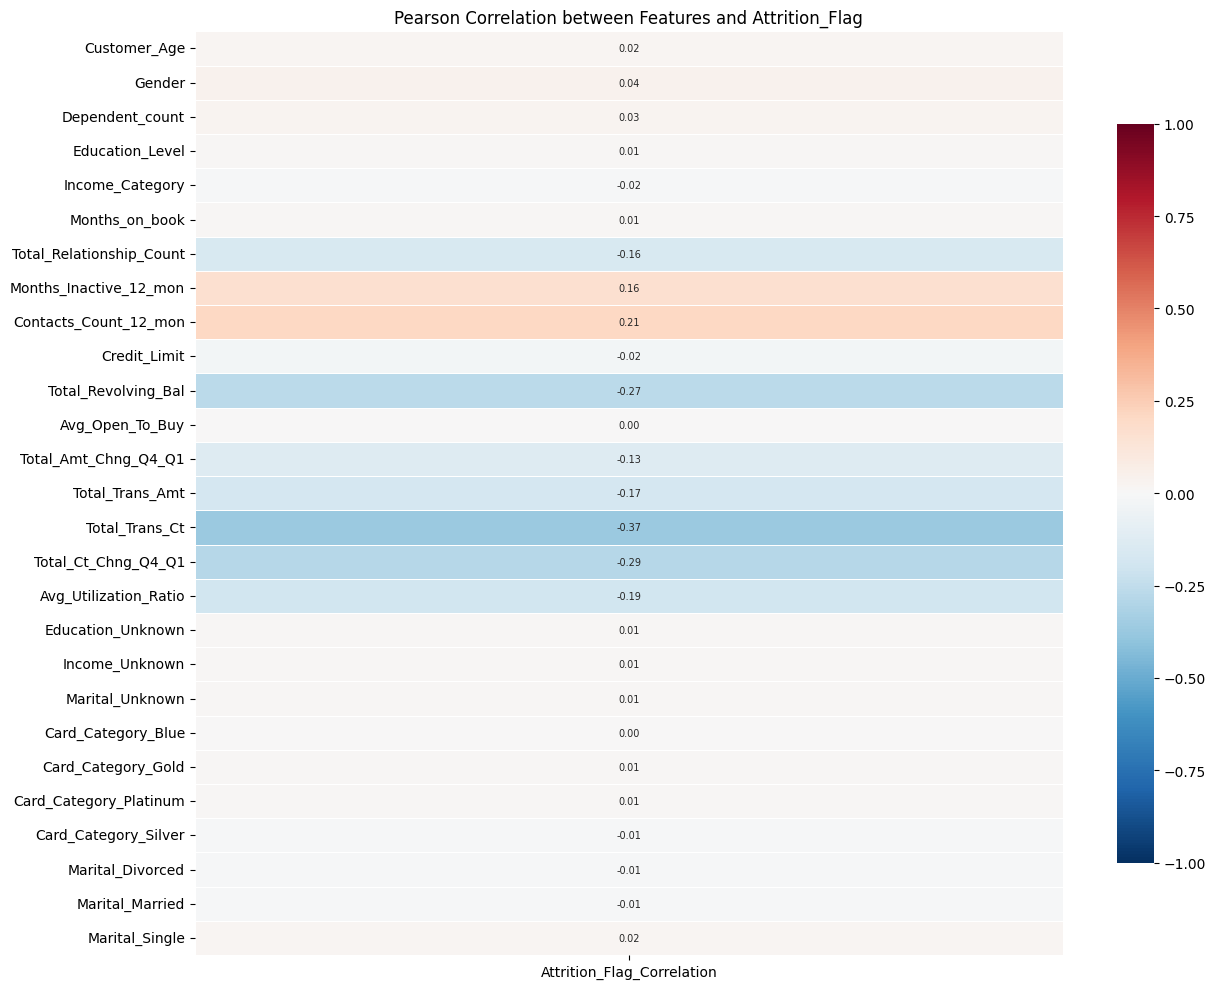

                     feature        score         pvalue  mutual_info  \
0             Total_Trans_Ct  1304.840615  4.672547e-265     0.117308   
1        Total_Ct_Chng_Q4_Q1   724.081801  7.826216e-153     0.097107   
2        Total_Revolving_Bal   624.638229  7.200815e-133     0.086718   
3      Contacts_Count_12_mon   357.053749   5.766715e-78     0.031237   
4      Avg_Utilization_Ratio   298.439252   1.074262e-65     0.056820   
5            Total_Trans_Amt   251.300721   9.267982e-56     0.158251   
6     Months_Inactive_12_mon   207.190324   2.099911e-46     0.020610   
7   Total_Relationship_Count   204.922922   6.377533e-46     0.012831   
8       Total_Amt_Chng_Q4_Q1   137.395987   1.772444e-31     0.031095   
9            Dependent_count     7.760686   5.351984e-03     0.002122   
10              Credit_Limit     4.658394   3.093137e-02     0.000305   
11              Customer_Age     2.412416   1.204155e-01     0.000000   
12            Months_on_book     0.534546   4.64723

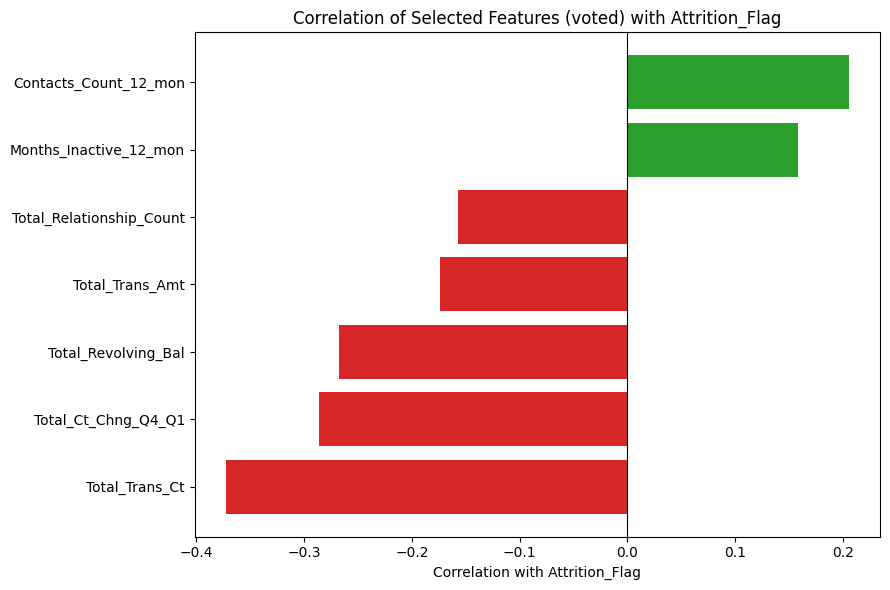

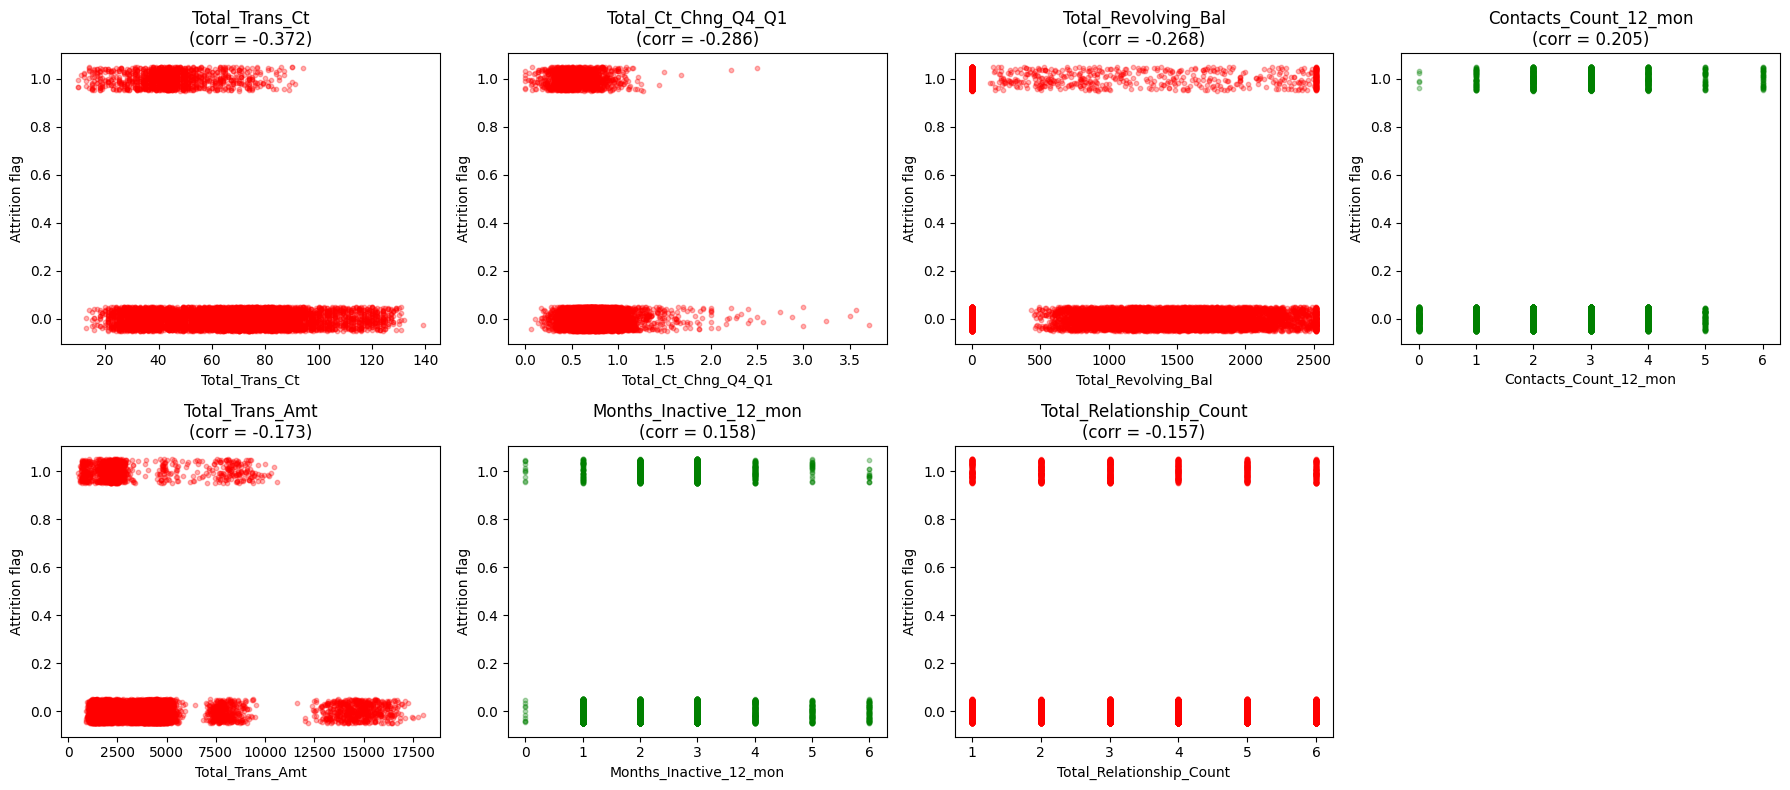

ฟีเจอร์: 25
Train: 8101 | Test: 2026

Income_Category             0.563
Card_Category_Blue          0.516
Card_Category_Silver        0.441
Gender                      0.421
Card_Category_Gold          0.234
Total_Trans_Amt             0.172
Card_Category_Platinum      0.106
Total_Trans_Ct              0.076
Total_Relationship_Count    0.071
Dependent_count             0.068
                 feature       score        pvalue  mutual_info
         Income_Category 3818.741260  0.000000e+00     0.211580
      Card_Category_Blue 2860.832605  0.000000e+00     0.116305
    Card_Category_Silver 1863.773769  0.000000e+00     0.084387
                  Gender 1793.463987  0.000000e+00     0.130455
      Card_Category_Gold  519.128770 1.972602e-111     0.030937
         Total_Trans_Amt  242.378319  7.156694e-54     0.106803
  Card_Category_Platinum   75.218274  5.036403e-18     0.006265
          Total_Trans_Ct   46.951240  7.810232e-12     0.039888
Total_Relationship_Count   42.747424  6.605692

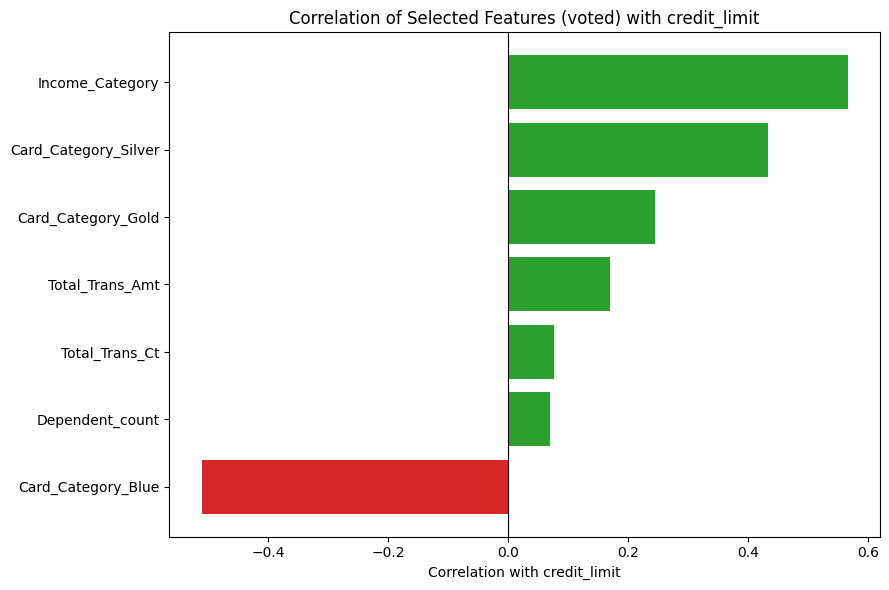

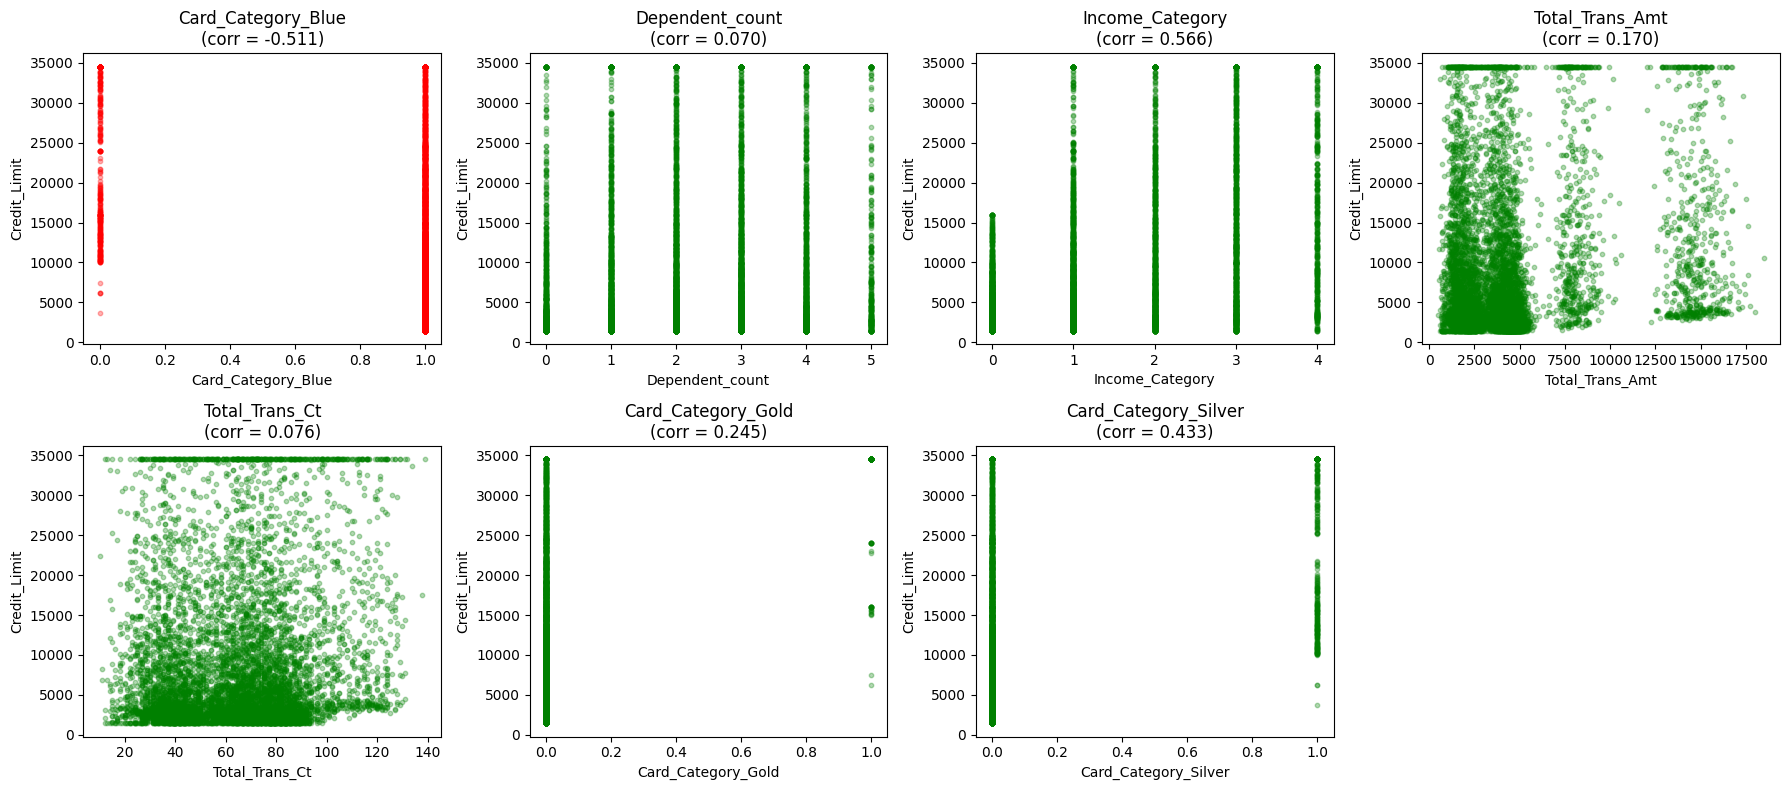

R² each fold: [0.5178384  0.55896333 0.51699789 0.55879163 0.56659464]
Mean R²: 0.5438 (+/- 0.0218)


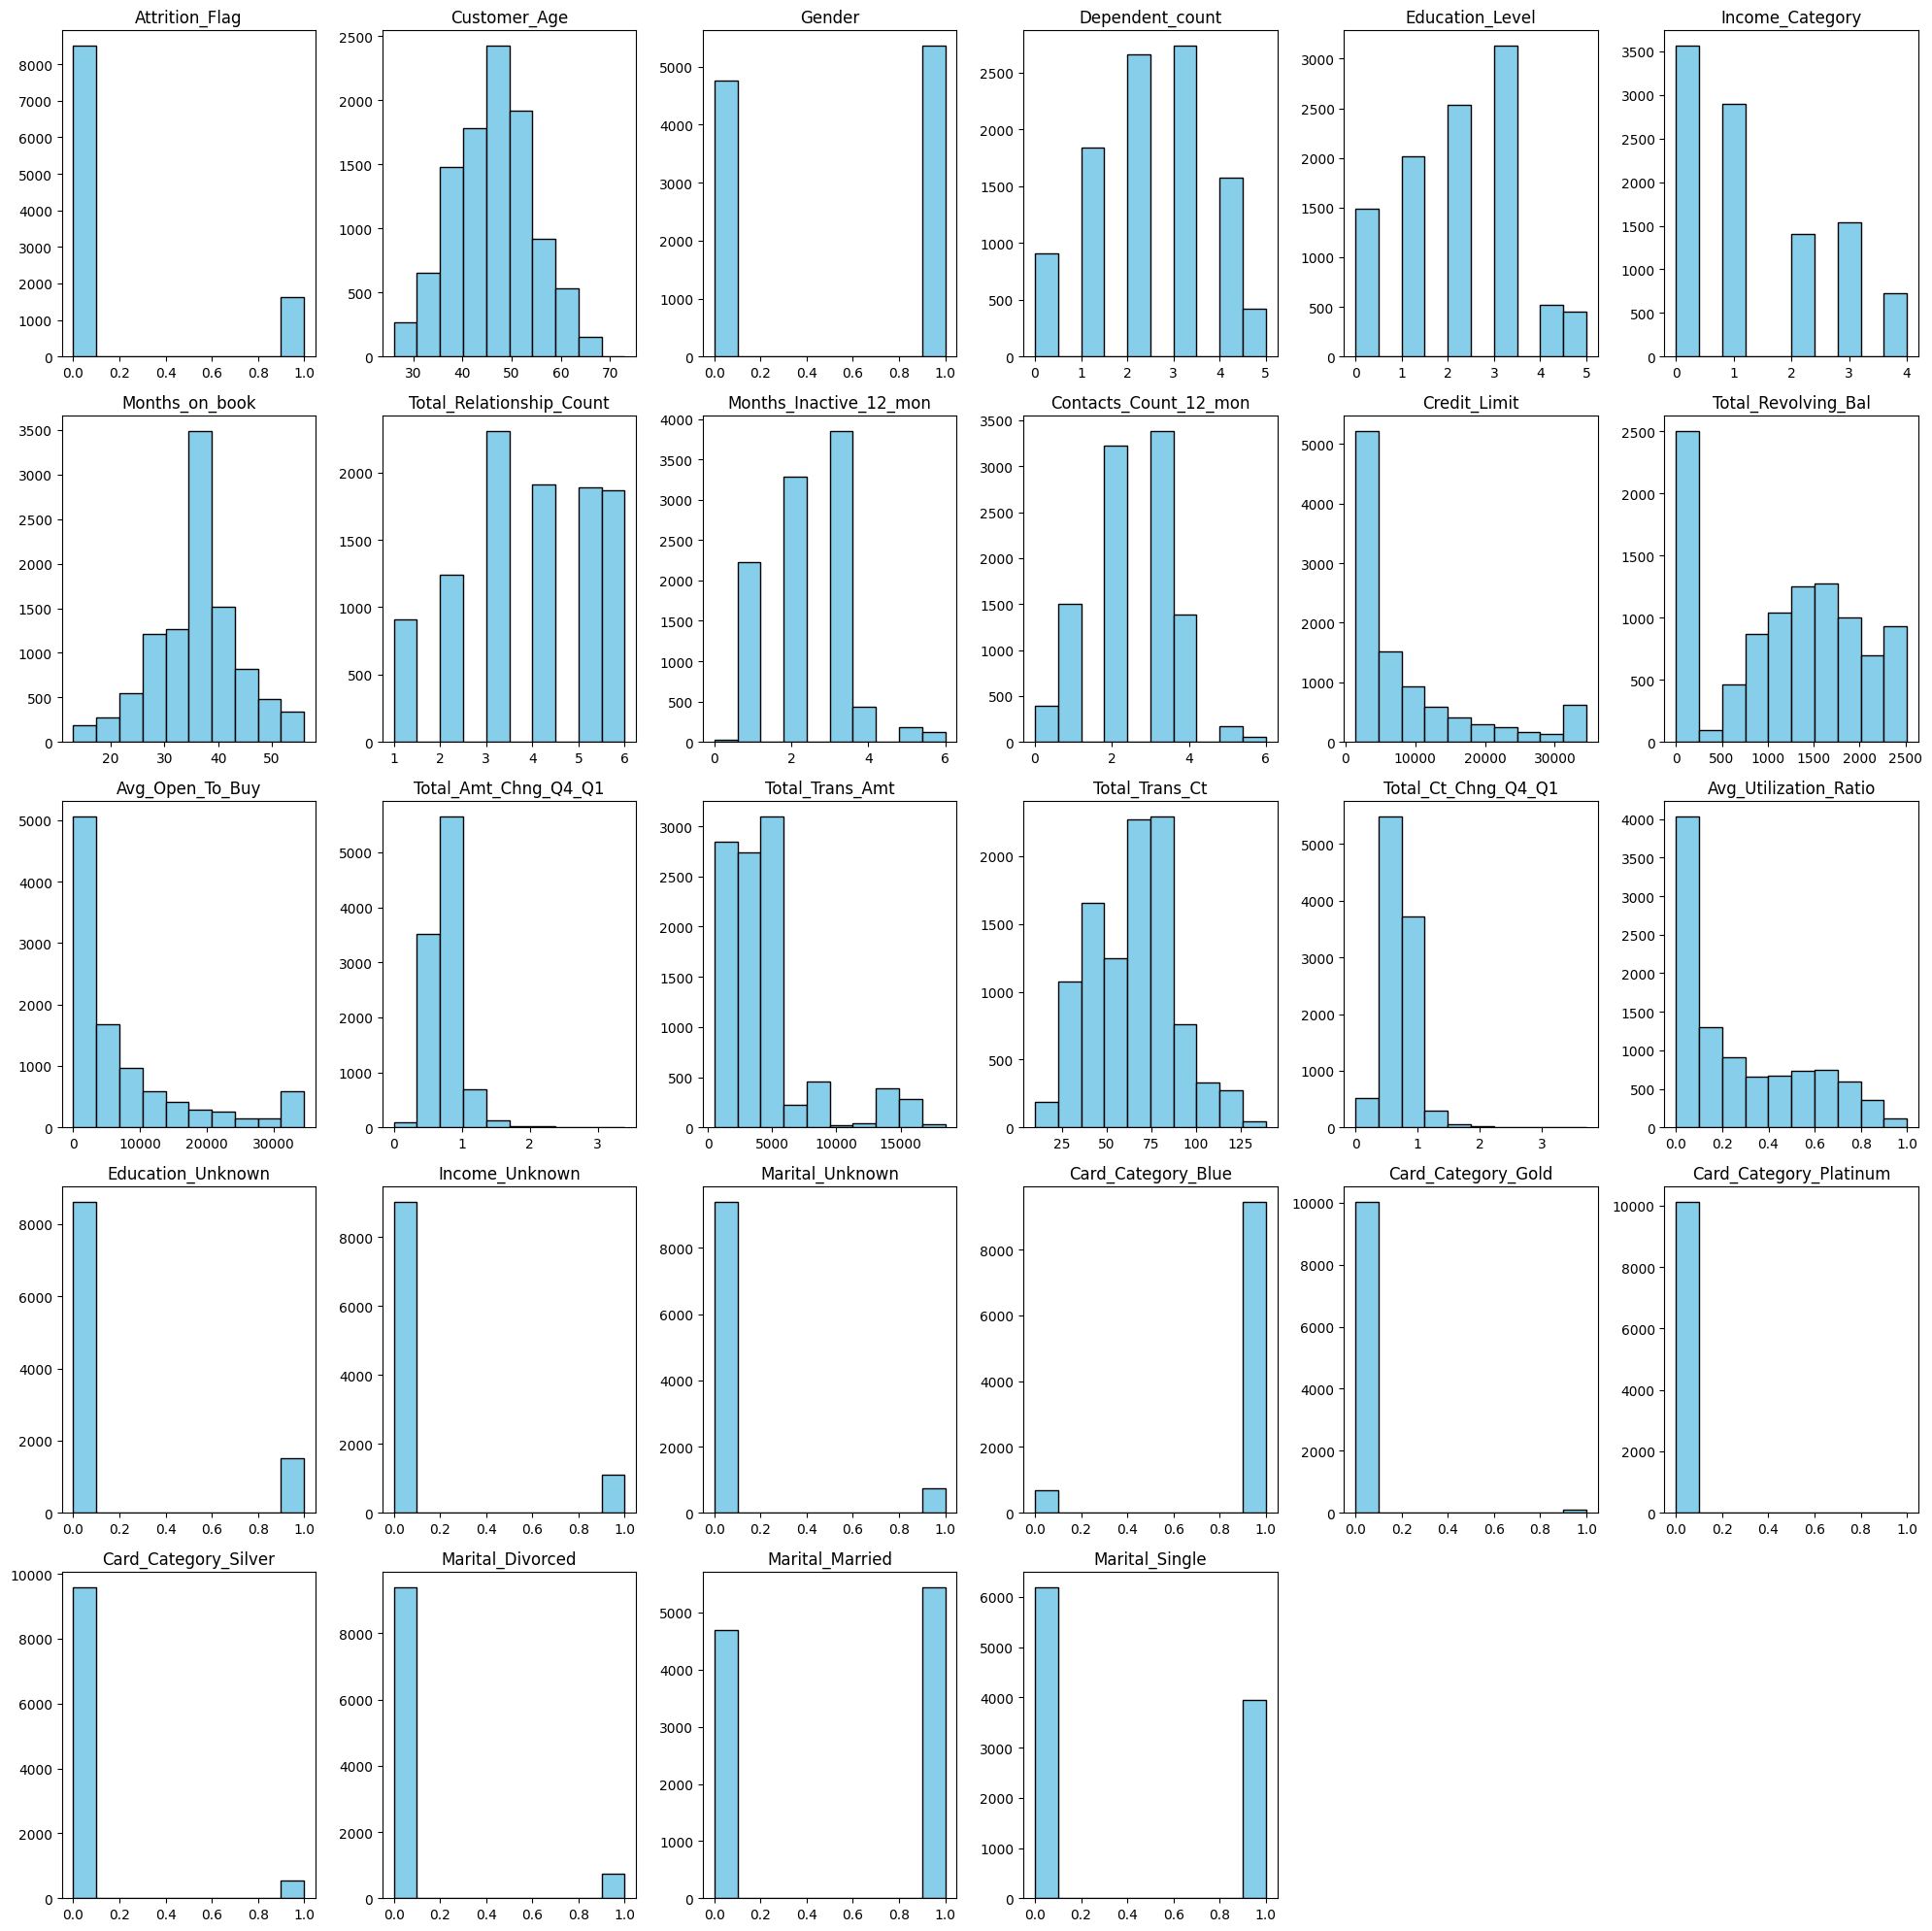

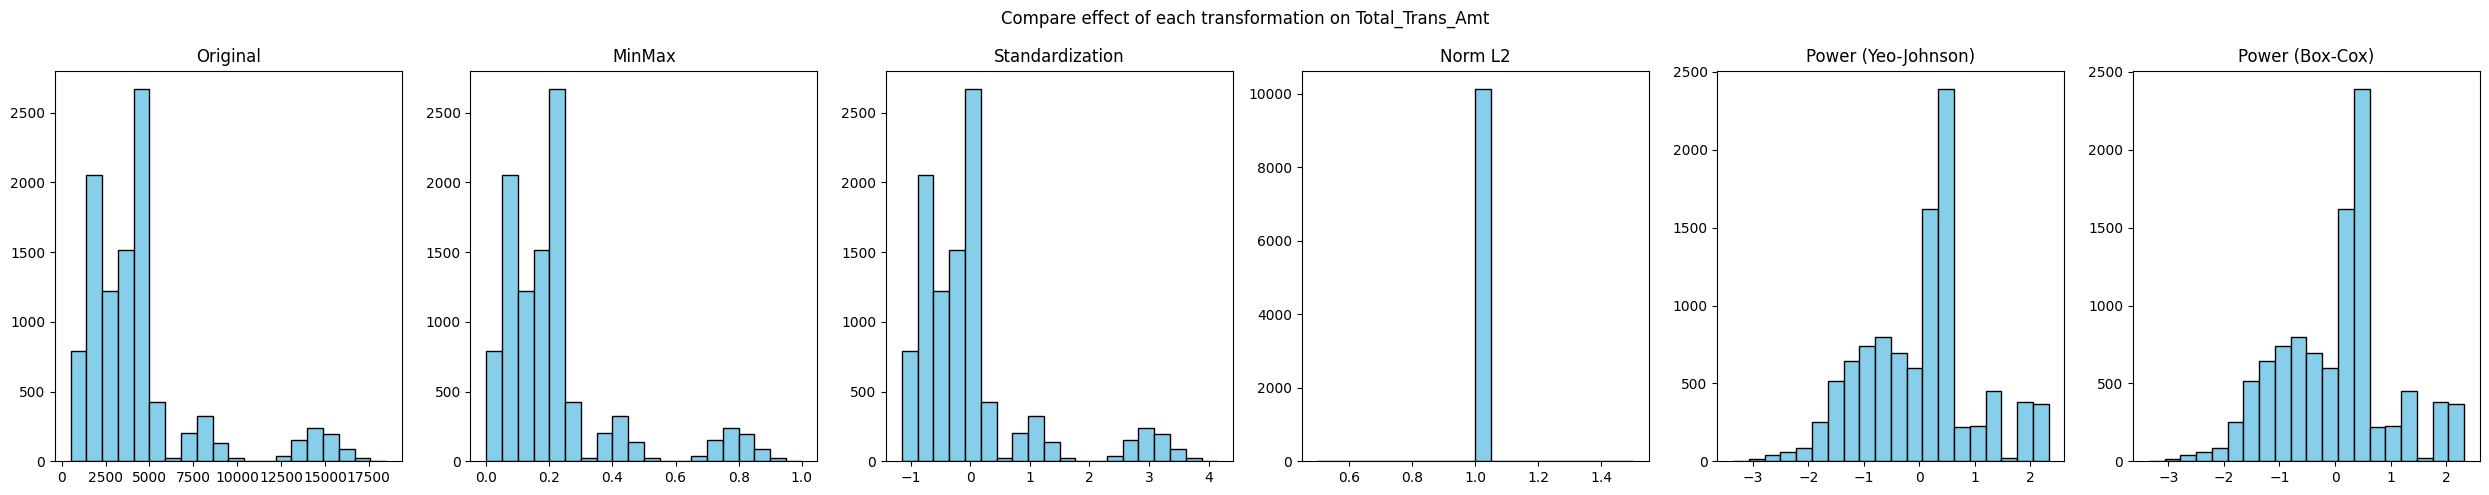

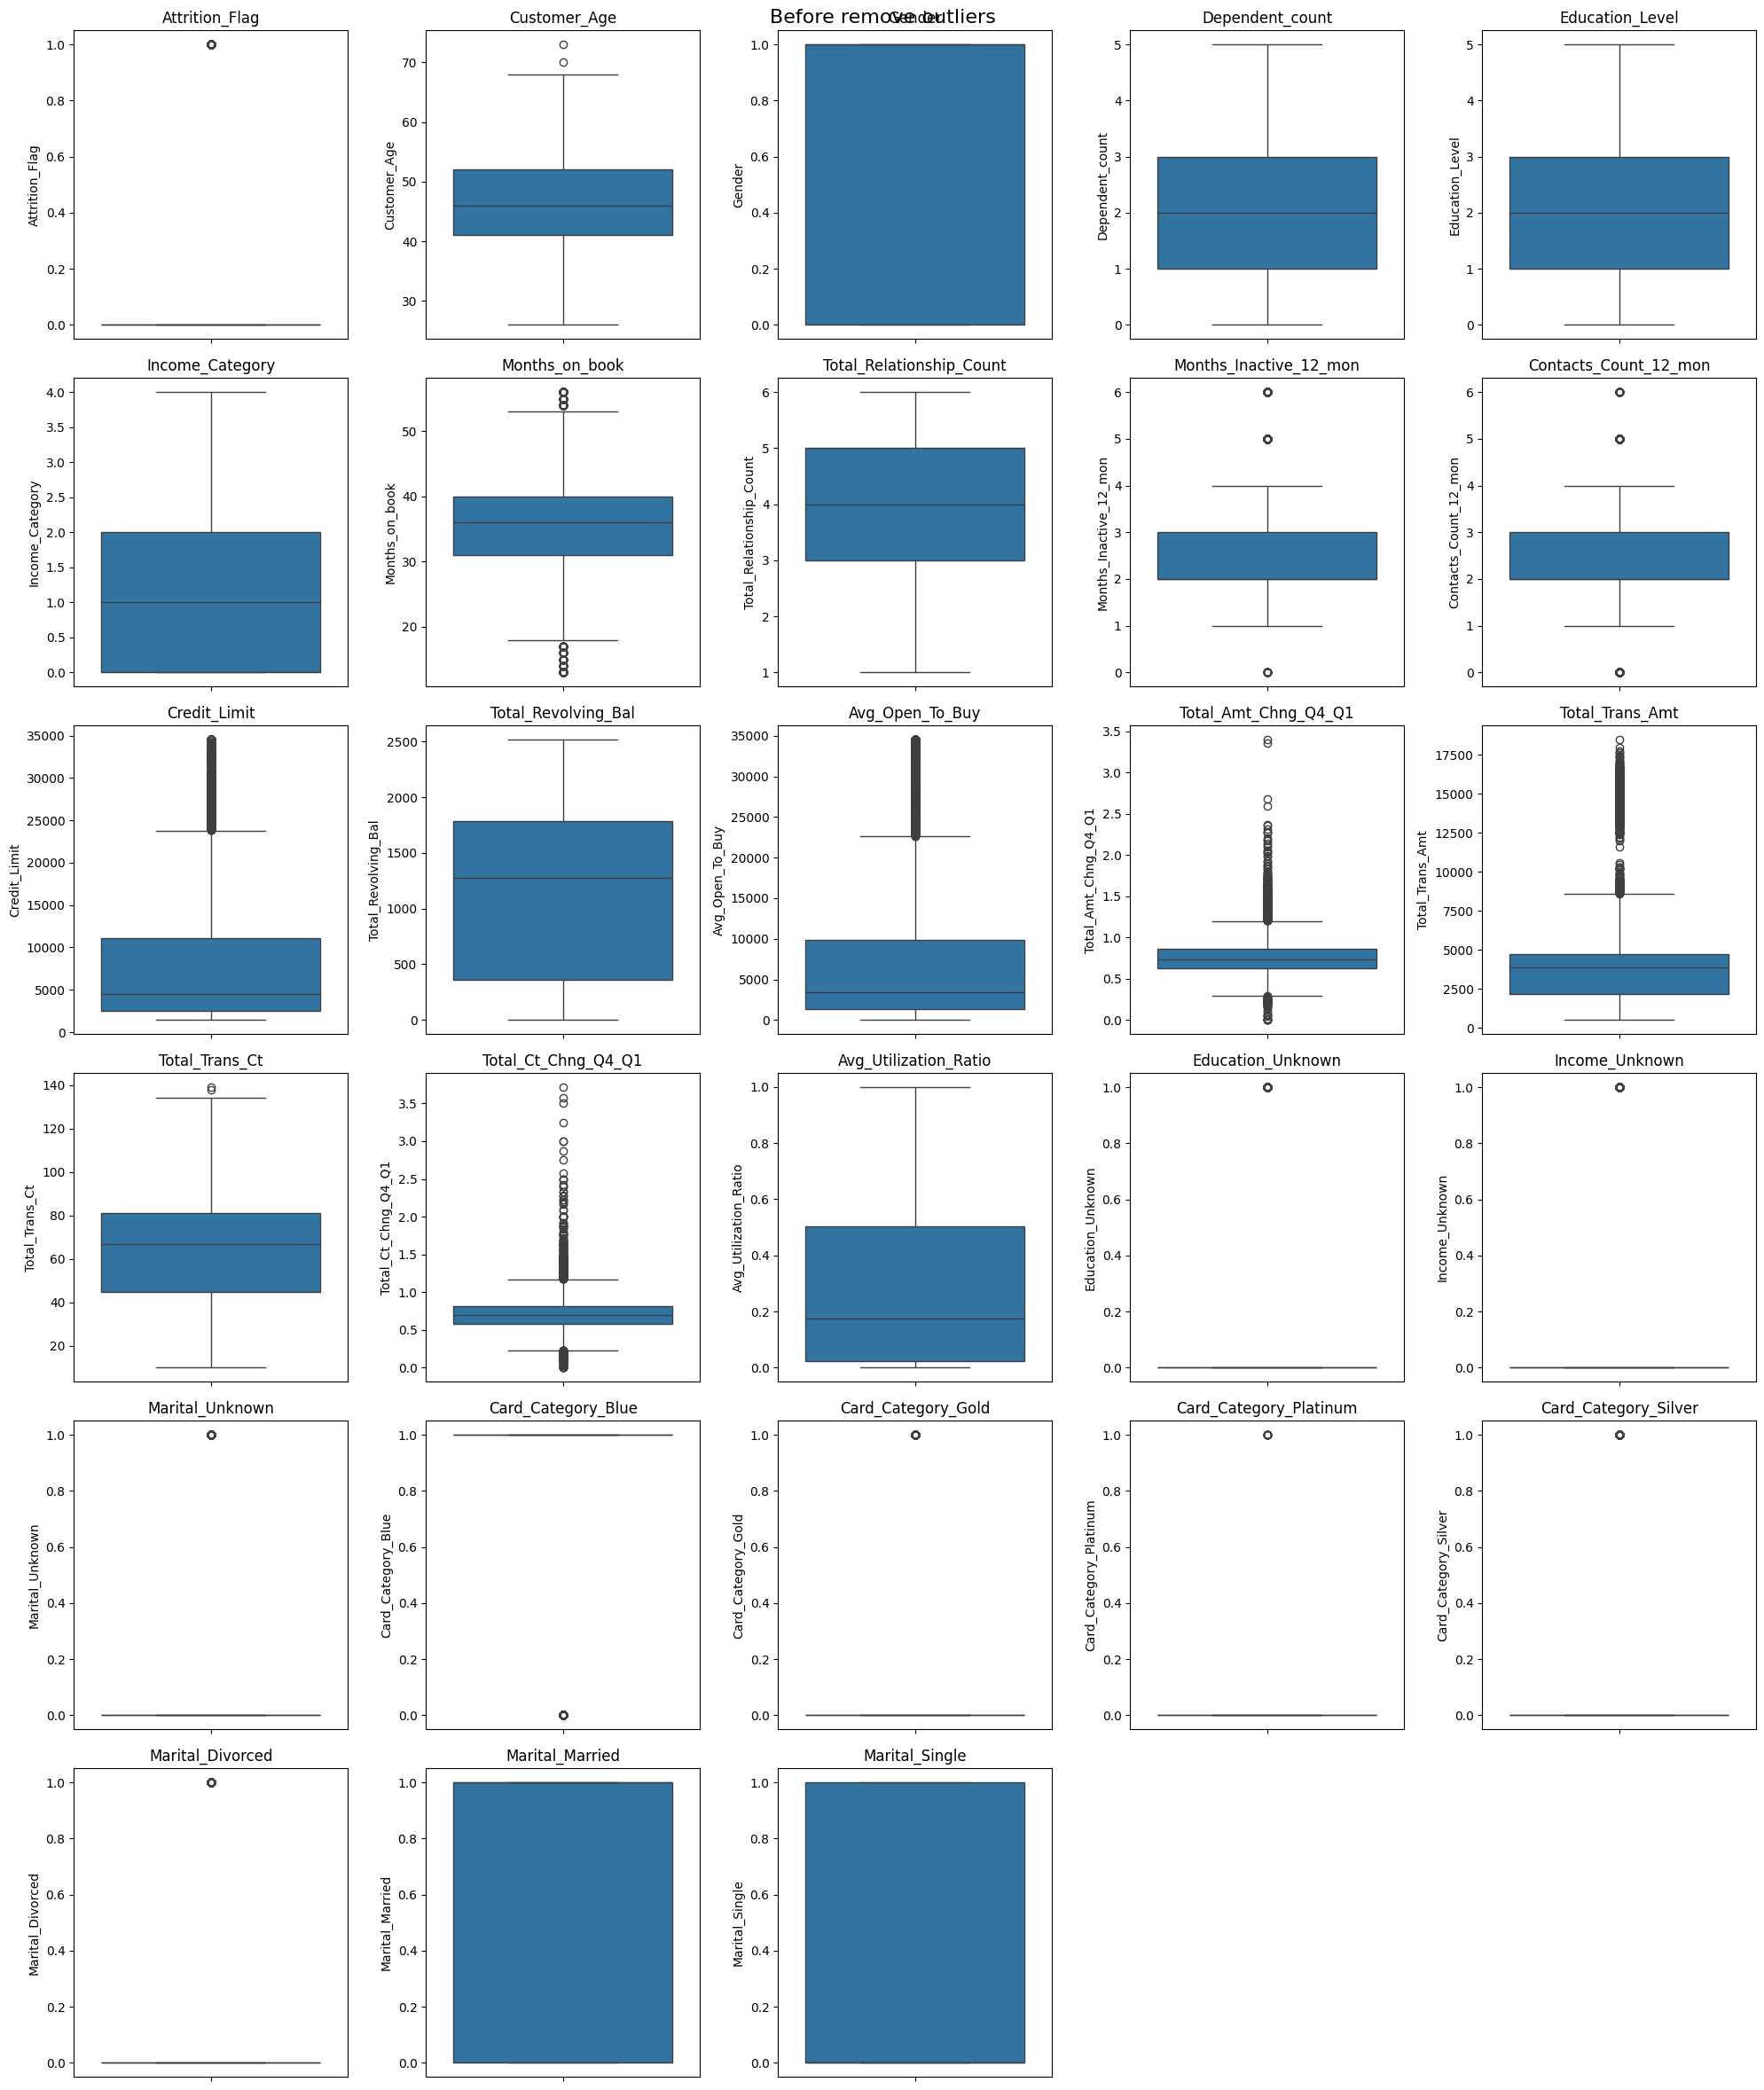

In [1]:
import import_ipynb
import data_analysis

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

df = pd.DataFrame(data_analysis.data)
# Plain NumPy arrays, 1D labels (avoids Series/2D shape problems everywhere below)
X_train = np.asarray(data_analysis.X_scaled, dtype=float)
X_test  = np.asarray(data_analysis.X_test_scaled, dtype=float)
y_train = np.asarray(data_analysis.y_train).ravel().astype(int)
y_test  = np.asarray(data_analysis.y_test).ravel().astype(int)

print(X_train.shape, X_test.shape, "positive rate (train/test):", y_train.mean().round(3), y_test.mean().round(3))

(8101, 27) (2026, 27) positive rate (train/test): 0.161 0.16


In [3]:
# แปลงคอลัมน์ฟีเจอร์ทั้งหมด (ยกเว้นคอลัมน์สุดท้ายที่เป็น target) ให้เป็น numeric
feature_cols = df.columns[:-1]
for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# ดึงค่า X และ y พร้อมบังคับ dtype ให้ชัดเจน
X = df.iloc[:, :-1].to_numpy(dtype=np.float64)
y = df.iloc[:, -1].to_numpy()

# ตรวจสอบคลาสที่มีอยู่จริงทั้งหมดใน y
classes = np.unique(y)
print("Classes found in y:", classes)

# คำนวณ Mean Vector ของแต่ละคลาสตามค่าที่มีอยู่จริง
mean_vectors = []
for cl in classes:
    mean_vec = np.mean(X[y == cl], axis=0)
    mean_vectors.append(mean_vec)
    print('Mean Vector class %s: %s\n' % (cl, mean_vec))

Classes found in y: [False  True]
Mean Vector class False: [1.55077620e-01 4.63979625e+01 5.22800776e-01 2.38842173e+00
 2.05805304e+00 1.33085382e+00 3.59607050e+01 3.83408797e+00
 2.33392626e+00 2.44825356e+00 8.39748352e+03 1.18740847e+03
 7.21007505e+03 7.67523448e-01 4.28264133e+03 6.30109961e+01
 7.14080369e-01 2.81606080e-01 1.45213454e-01 1.08020699e-01
 1.21119017e-01 9.39844761e-01 9.37904269e-03 1.61707633e-03
 4.91591203e-02 1.20957309e-01 8.79042691e-01]

Mean Vector class True: [1.69414152e-01 4.62130358e+01 5.38929749e-01 2.27998986e+00
 2.04235354e+00 1.26528024e+00 3.58777581e+01 3.77884859e+00
 2.35252346e+00 2.46639615e+00 8.99968476e+03 1.12424144e+03
 7.87544332e+03 7.48048187e-01 4.59455440e+03 6.77565306e+01
 7.09308395e-01 2.64365965e-01 1.57494294e-01 1.12604616e-01
 0.00000000e+00 9.19097134e-01 1.47096120e-02 2.53613999e-03
 6.36571139e-02 0.00000000e+00 0.00000000e+00]



In [4]:

num_features = X.shape[1]
S_W = np.zeros((num_features, num_features))

for cl, mv in zip(classes, mean_vectors):
    class_sc_mat = np.zeros((num_features, num_features))
    for row in X[y == cl]:
        row = row.reshape(num_features, 1)
        mv_col = mv.reshape(num_features, 1)
        class_sc_mat += (row - mv_col).dot((row - mv_col).T)
    S_W += class_sc_mat

print('within-class Scatter Matrix:\n', S_W)

within-class Scatter Matrix:
 [[ 1.36511191e+03  5.49046091e+02  6.86289833e+01  9.54703341e+01
   9.20349712e+01 -5.54960125e+01  4.09341483e+02 -8.65161222e+02
   5.72279045e+02  8.40572213e+02 -8.27639916e+05 -7.95035008e+05
  -3.26049075e+04 -1.06163175e+02 -2.14060838e+06 -3.25819077e+04
  -2.56635081e+02 -1.82309696e+02  1.15341094e+01  8.18826673e+00
   1.28468629e+01  3.73198889e+00  2.17947726e+00  1.75508229e+00
  -7.66654844e+00  5.00194049e+00 -5.00194049e+00]
 [ 5.49046091e+02  6.50708664e+05  7.08686301e+02 -1.29390974e+04
   1.33554496e+02  2.66993335e+03  5.11433388e+05 -1.40392331e+03
   4.46808777e+03 -1.64892477e+03  2.09512496e+06  9.49700937e+05
   1.14542402e+06 -1.11269968e+03 -1.26698070e+07 -1.25737547e+05
  -2.36808839e+02  1.51541026e+02  1.61334483e+02 -5.54268164e+01
  -6.21073900e+02  4.29000451e+02 -1.00437898e+02  2.38900176e+01
  -3.52452571e+02 -9.58675938e+02  9.58675938e+02]
 [ 6.86289833e+01  7.08686301e+02  2.52255937e+03 -2.57459072e+01
   6.93132

In [5]:
overall_mean = np.mean(X, axis=0).reshape(num_features, 1)
S_B = np.zeros((num_features, num_features))

for cl, mean_vec in zip(classes, mean_vectors):
    n = X[y == cl].shape[0]
    mean_vec_col = mean_vec.reshape(num_features, 1)
    S_B += n * (mean_vec_col - overall_mean).dot((mean_vec_col - overall_mean).T)

print('between-class Scatter Matrix:\n', S_B)

between-class Scatter Matrix:
 [[ 4.94884287e-01 -6.38350544e+00  5.56757741e-01 -3.74297164e+00
  -5.41932801e-01 -2.26354120e+00 -2.86325616e+00 -1.90681397e+00
   6.41958673e-01  6.26265925e-01  2.07874491e+04 -2.18046959e+03
   2.29679187e+04 -6.72268623e-01  1.07669607e+04  1.63811613e+02
  -1.64724285e-01 -5.95113387e-01  4.23923621e-01  1.58232730e-01
  -4.18092034e+00 -7.16189547e-01  1.84006493e-01  3.17252574e-02
   5.00457796e-01 -4.17533834e+00 -3.03437690e+01]
 [-6.38350544e+00  8.23407468e+01 -7.18161025e+00  4.82805384e+01
   6.99038357e+00  2.91973860e+01  3.69331008e+01  2.45959665e+01
  -8.28061588e+00 -8.07819535e+00 -2.68137013e+05  2.81258465e+04
  -2.96262860e+05  8.67158350e+00 -1.38882874e+05 -2.11300369e+03
   2.12477623e+00  7.67635920e+00 -5.46818481e+00 -2.04104175e+00
   5.39296326e+01  9.23811887e+00 -2.37349716e+00 -4.09223649e-01
  -6.45539806e+00  5.38576304e+01  3.91403849e+02]
 [ 5.56757741e-01 -7.18161025e+00  6.26366991e-01 -4.21094080e+00
  -6.0968

In [6]:
# Solving the generalized eigenvalue problem for the matrix S_W^{-1} S_B
# Use the actual feature dimension instead of a hard-coded 2x2 assumption.
A = np.linalg.pinv(S_W).dot(S_B)
eig_vals, eig_vecs = np.linalg.eig(A)

for i in range(len(eig_vals)):
    eigvec_sc = eig_vecs[:, i].reshape(num_features, 1)
    print('\nEigenvector {}: \n{}'.format(i + 1, eigvec_sc.real))
    print('Eigenvalue {:}: {:.2e}'.format(i + 1, eig_vals[i].real))


Eigenvector 1: 
[[ 8.13927277e-02]
 [ 1.42128485e-03]
 [-2.56333195e-02]
 [-1.56780043e-02]
 [-5.46792421e-04]
 [-1.38553683e-02]
 [-4.08157796e-04]
 [-1.39410385e-03]
 [-7.16214512e-04]
 [ 5.96352299e-03]
 [-2.63972254e-02]
 [ 2.63779046e-02]
 [ 2.63987112e-02]
 [-7.52431748e-02]
 [-1.46687133e-05]
 [ 3.66771243e-03]
 [ 4.78738639e-02]
 [ 3.77917255e-02]
 [ 3.78083585e-02]
 [-6.15967766e-03]
 [-2.72199415e-01]
 [-6.48533902e-02]
 [ 5.87238015e-02]
 [ 3.67595790e-02]
 [-3.06301273e-02]
 [ 6.69048359e-01]
 [-6.69048362e-01]]
Eigenvalue 1: 5.61e-01

Eigenvector 2: 
[[ 8.13856346e-02]
 [ 1.42116100e-03]
 [-2.56310857e-02]
 [-1.56766380e-02]
 [-5.46744772e-04]
 [-1.38541609e-02]
 [-4.08122228e-04]
 [-1.39398233e-03]
 [-7.16152093e-04]
 [ 5.96300332e-03]
 [-2.82497242e-02]
 [ 2.68563588e-02]
 [ 2.72782346e-02]
 [-7.52366179e-02]
 [-1.46674350e-05]
 [ 3.66739281e-03]
 [ 4.78696920e-02]
 [ 3.77884323e-02]
 [ 3.78050638e-02]
 [-6.15914089e-03]
 [-2.72175694e-01]
 [-6.48477408e-02]
 [ 5.871867

In [7]:
# Make a list of (eigenvalue, eigenvector) tuples
eig_pairs = [(np.abs(eig_vals[i]), eig_vecs[:,i]) for i in range(len(eig_vals))]

# Sort the (eigenvalue, eigenvector) tuples from high to low
eig_pairs = sorted(eig_pairs, key=lambda k: k[0], reverse=True)

# Visually confirm that the list is correctly sorted by decreasing eigenvalues

print('Eigenvalues in decreasing order:\n')
for i in eig_pairs:
    print(i[0])

Eigenvalues in decreasing order:

0.5607301726890184
0.00014517418923197815
2.6073627555524746e-06
1.2998564108520545e-06
4.6503006479963696e-15
1.2882910802687255e-15
1.2577147826785835e-15
4.05212112483403e-16
4.0022792017367e-16
2.9766753408066654e-16
2.9766753408066654e-16
2.503265571235761e-16
1.1481582398967512e-16
1.1481582398967512e-16
4.916857650280808e-17
4.916857650280808e-17
1.8584462063580385e-17
1.7199674242425556e-17
1.3279132996239828e-17
1.3279132996239828e-17
1.1292404730074855e-17
1.0709536674009789e-17
1.0709536674009789e-17
2.6474650064426514e-18
6.931687712435294e-19
5.8733845111120805e-19
5.8733845111120805e-19


In [8]:
print('Variance explained:\n')
eigv_sum = np.sum(np.abs(eig_vals))
if np.isclose(eigv_sum, 0):
    raise ValueError('LDA failed: total eigenvalue sum is zero; the within-class scatter is singular.')

for i, j in enumerate(eig_pairs):    print('eigenvalue {0:}: {1:.2%}'.format(i + 1, (j[0] / eigv_sum).real))

Variance explained:

eigenvalue 1: 99.97%
eigenvalue 2: 0.03%
eigenvalue 3: 0.00%
eigenvalue 4: 0.00%
eigenvalue 5: 0.00%
eigenvalue 6: 0.00%
eigenvalue 7: 0.00%
eigenvalue 8: 0.00%
eigenvalue 9: 0.00%
eigenvalue 10: 0.00%
eigenvalue 11: 0.00%
eigenvalue 12: 0.00%
eigenvalue 13: 0.00%
eigenvalue 14: 0.00%
eigenvalue 15: 0.00%
eigenvalue 16: 0.00%
eigenvalue 17: 0.00%
eigenvalue 18: 0.00%
eigenvalue 19: 0.00%
eigenvalue 20: 0.00%
eigenvalue 21: 0.00%
eigenvalue 22: 0.00%
eigenvalue 23: 0.00%
eigenvalue 24: 0.00%
eigenvalue 25: 0.00%
eigenvalue 26: 0.00%
eigenvalue 27: 0.00%


In [9]:
# Choosing k eigenvectors with the largest eigenvalues
# Make this work for the actual number of features instead of assuming exactly 2 features.
W = np.hstack([eig_pairs[0][1].reshape(num_features, 1)])
print('Matrix W:\n', W.real)

Matrix W:
 [[ 8.13927277e-02]
 [ 1.42128485e-03]
 [-2.56333195e-02]
 [-1.56780043e-02]
 [-5.46792421e-04]
 [-1.38553683e-02]
 [-4.08157796e-04]
 [-1.39410385e-03]
 [-7.16214512e-04]
 [ 5.96352299e-03]
 [-2.63972254e-02]
 [ 2.63779046e-02]
 [ 2.63987112e-02]
 [-7.52431748e-02]
 [-1.46687133e-05]
 [ 3.66771243e-03]
 [ 4.78738639e-02]
 [ 3.77917255e-02]
 [ 3.78083585e-02]
 [-6.15967766e-03]
 [-2.72199415e-01]
 [-6.48533902e-02]
 [ 5.87238015e-02]
 [ 3.67595790e-02]
 [-3.06301273e-02]
 [ 6.69048359e-01]
 [-6.69048362e-01]]


In [10]:
#Transforming the samples onto the new subspace
X_lda = X.dot(W)

In [11]:
X_lda

array([[-0.63134636+0.j],
       [ 0.04622226+0.j],
       [-0.80538116+0.j],
       ...,
       [-0.57710885+0.j],
       [-0.82703901+0.j],
       [-0.57926671+0.j]])

In [12]:
class CatBoostClassifier:
    def __init__(self, learning_rate=0.1, n_estimators=100, max_depth=3,
                 l2_leaf_reg=3.0, border_count=32, cat_features=None,
                 prior_weight=1.0, random_state=0):
        self.learning_rate = learning_rate
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.l2_leaf_reg = l2_leaf_reg
        self.border_count = border_count
        self.cat_features = cat_features
        self.prior_weight = prior_weight
        self.random_state = random_state

    # ---------------- helpers ----------------
    @staticmethod
    def _softmax(z):
        z = z - z.max(axis=1, keepdims=True)          # numerically stable
        e = np.exp(z)
        return e / e.sum(axis=1, keepdims=True)

    def _as_array(self, X):
        X = np.asarray(X)
        if self._cats:                                 # mixed types -> object copy
            X = np.array(X, dtype=object, copy=True)
        else:
            X = X.astype(float)
        return X

    def _ordered_ts(self, codes, target, perm, prior):
        """TS for each row from rows BEFORE it in `perm` only."""
        cp, tp = codes[perm], target[perm]
        idx = np.argsort(cp, kind="stable")
        sc, st = cp[idx], tp[idx]
        n = len(sc)
        starts = np.r_[0, np.flatnonzero(np.diff(sc)) + 1]
        grp_start = np.repeat(starts, np.diff(np.r_[starts, n]))
        cs = np.cumsum(st)
        base = np.where(grp_start > 0, cs[grp_start - 1], 0.0)
        sum_before = cs - st - base
        cnt_before = np.arange(n) - grp_start
        ts_sorted = (sum_before + self.prior_weight * prior) / (cnt_before + self.prior_weight)
        tmp = np.empty(n)
        tmp[idx] = ts_sorted
        out = np.empty(n)
        out[perm] = tmp
        return out

    def _matrix(self, X, train):
        """Numeric matrix: numeric cols as-is, each cat col -> K TS columns."""
        n, d = X.shape
        cols = []
        for j in range(d):
            if j not in self._cats:
                cols.append(X[:, j].astype(float))
            elif train:
                cols.extend(self._train_ts[j])
            else:
                m = self._cat_stats[j]
                vals = X[:, j].astype(str)
                for k in range(self.K):
                    out = np.full(n, self._priors[k])
                    for i, v in enumerate(vals):
                        if v in m:
                            s, c = m[v]
                            out[i] = (s[k] + self.prior_weight * self._priors[k]) / (c + self.prior_weight)
                    cols.append(out)
        return np.column_stack(cols)

    def _quantize(self, M, fit=False):
        n, d = M.shape
        if fit:
            qs = np.linspace(0, 1, self.border_count + 1)[1:-1]
            self._borders = [np.unique(np.quantile(M[:, j], qs)) for j in range(d)]
        Xb = np.empty((n, d), dtype=np.int64)
        for j in range(d):
            Xb[:, j] = np.searchsorted(self._borders[j], M[:, j], side="left")
        return Xb

    # ---------------- one oblivious tree ----------------
    def _build_tree(self, Xb, G, H):
        n, d = Xb.shape
        K = self.K
        B = max(len(b) for b in self._borders) + 1
        leaf = np.zeros(n, dtype=np.int64)
        splits = []
        for level in range(self.max_depth):
            L = 2 ** level
            best_score, best = -np.inf, None
            for j in range(d):
                nb = len(self._borders[j]) + 1
                if nb < 2:
                    continue
                key = leaf * B + Xb[:, j]
                score = np.zeros(nb - 1)
                for k in range(K):
                    g = np.bincount(key, weights=G[:, k], minlength=L * B).reshape(L, B)
                    h = np.bincount(key, weights=H[:, k], minlength=L * B).reshape(L, B)
                    gl = np.cumsum(g, 1)[:, :nb - 1]
                    hl = np.cumsum(h, 1)[:, :nb - 1]
                    gr = g.sum(1, keepdims=True) - gl
                    hr = h.sum(1, keepdims=True) - hl
                    score += (gl**2 / (hl + self.l2_leaf_reg)
                              + gr**2 / (hr + self.l2_leaf_reg)).sum(0)
                t = int(np.argmax(score))
                if score[t] > best_score:
                    best_score, best = score[t], (j, t)
            if best is None:
                break
            splits.append(best)
            leaf = leaf * 2 + (Xb[:, best[0]] > best[1])
        L = 2 ** len(splits)
        values = np.zeros((L, K))
        for k in range(K):
            g = np.bincount(leaf, weights=G[:, k], minlength=L)
            h = np.bincount(leaf, weights=H[:, k], minlength=L)
            values[:, k] = g / (h + self.l2_leaf_reg)      # Newton step per leaf
        return splits, values, leaf

    @staticmethod
    def _leaf_index(Xb, splits):
        idx = np.zeros(len(Xb), dtype=np.int64)
        for j, t in splits:
            idx = idx * 2 + (Xb[:, j] > t)
        return idx

    # ---------------- public API ----------------
    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        self._cats = set(self.cat_features or [])
        X = self._as_array(X)
        self.classes_, yi = np.unique(np.asarray(y), return_inverse=True)
        self.K = len(self.classes_)
        n = len(yi)
        one_hot_y = np.eye(self.K)[yi]
        self._priors = one_hot_y.mean(axis=0)

        # ordered target statistics (single random permutation)
        perm = rng.permutation(n)
        self._train_ts, self._cat_stats = {}, {}
        for j in self._cats:
            uniq, codes = np.unique(X[:, j].astype(str), return_inverse=True)
            self._train_ts[j] = [self._ordered_ts(codes, one_hot_y[:, k], perm, self._priors[k])
                                 for k in range(self.K)]
            self._cat_stats[j] = {u: (one_hot_y[codes == c].sum(0), (codes == c).sum())
                                  for c, u in enumerate(uniq)}

        Xb = self._quantize(self._matrix(X, train=True), fit=True)

        self._base = np.log(np.clip(self._priors, 1e-9, None))
        predictions = np.tile(self._base, (n, 1))
        self.trees = []
        for _ in range(self.n_estimators):
            P = self._softmax(predictions)
            G = one_hot_y - P                  # residuals (negative gradient)
            H = P * (1 - P)                    # diagonal hessian
            splits, values, leaf = self._build_tree(Xb, G, H)
            predictions += self.learning_rate * values[leaf]
            self.trees.append((splits, values))
        return self

    def _raw(self, samples):
        X = self._as_array(samples)
        Xb = self._quantize(self._matrix(X, train=False))
        out = np.tile(self._base, (len(Xb), 1))
        for splits, values in self.trees:
            out += self.learning_rate * values[self._leaf_index(Xb, splits)]
        return out

    def predict_proba(self, samples):
        return self._softmax(self._raw(samples))

    def predict(self, samples):
        return self.classes_[np.argmax(self._raw(samples), axis=1)]



In [19]:
class AdaBoost:
    def __init__(self, regression=False, n_estimators=50, learning_rate=1.0, random_state=0):
        self.regression = regression
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.random_state = random_state
        self.stumps = []
        self.weights = []
        self.classes_ = None
        self._label_to_index = {}

    def _update_weights(self, args):
        if self.regression:
            weights, beta, loss_function = args
            weights *= beta ** (1 - loss_function)
        else:
            weights, wrong_predictions, stump_weight = args
            weights[wrong_predictions] *= np.exp(stump_weight)

        return weights

    @staticmethod
    def _normalize(weights: np.ndarray):
        return weights / sum(weights)

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self._label_to_index = {label: idx for idx, label in enumerate(self.classes_)}
        n_samples = len(y)
        self.K = len(self.classes_)
        weights = np.ones(n_samples) / n_samples

        for _ in range(self.n_estimators):
            if self.regression:
                stump = DecisionTreeRegressor(max_depth=3, random_state=self.random_state)
                stump_predictions = stump.fit(X, y, sample_weight=weights).predict(X)

                abs_instance_errors = abs(stump_predictions - y)
                adjusted_instance_errors = abs_instance_errors / max(abs_instance_errors)
                adjusted_stump_error = sum(weights * adjusted_instance_errors)

                if adjusted_stump_error >= 0.5:
                    self.stumps.pop(-1)
                    break

                beta = adjusted_stump_error / (1 - adjusted_stump_error)
                stump_weight = self.learning_rate * np.log(1 / beta)
                args = [weights, beta, adjusted_instance_errors]
            else:
                stump = DecisionTreeClassifier(max_depth=1, random_state=self.random_state)
                stump_predictions = stump.fit(X, y, sample_weight=weights).predict(X)

                wrong_predictions = stump_predictions != y
                r = sum(weights[wrong_predictions])
                stump_weight = self.learning_rate * np.log((1 - r) / r) + np.log(self.K - 1)
                args = [weights, wrong_predictions, stump_weight]

            self.stumps.append(stump)
            self.weights.append(stump_weight)
            weights = self._update_weights(args)
            weights = self._normalize(weights)

    def _max_weighted_votes(self, samples):
        n_samples = len(samples)
        sample_indexes = np.array(range(n_samples))
        prediction_weights = np.zeros((n_samples, self.K))

        for i in range(self.n_estimators):
            stump_prediction = np.asarray(self.stumps[i].predict(samples))
            mapped_predictions = np.array([self._label_to_index[pred] for pred in stump_prediction], dtype=int)
            prediction_weights[sample_indexes, mapped_predictions] += self.weights[i]

        best_index = np.argmax(prediction_weights, axis=1)
        return self.classes_[best_index]

    def _weighted_median_prediction(self, samples):
        n_samples = len(samples)
        sample_indexes = np.arange(n_samples)
        predictions = np.array([stump.predict(samples) for stump in self.stumps]).T
        sorted_pred_indexes = np.argsort(predictions, axis=1)

        cumsum_weights = np.array(self.weights)[sorted_pred_indexes].cumsum(axis=1)
        is_over_median = cumsum_weights >= 0.5 * sum(self.weights)
        median_indexes = is_over_median.argmax(axis=1)
        median_prediction_indexes = sorted_pred_indexes[sample_indexes, median_indexes]

        return predictions[sample_indexes, median_prediction_indexes]

    def predict_proba(self, samples):
        n_samples = len(samples)
        scores = np.zeros((n_samples, self.K))

        for stump, weight in zip(self.stumps, self.weights):
            predictions = np.asarray(stump.predict(samples))
            mapped_predictions = np.array([self._label_to_index[pred] for pred in predictions], dtype=int)

            for i, pred_idx in enumerate(mapped_predictions):
                scores[i, pred_idx] += weight

        scores = scores / scores.sum(axis=1, keepdims=True)
        return scores

    def predict(self, samples):
        if self.regression:
            return self._weighted_median_prediction(samples)
        else:
            return self._max_weighted_votes(samples)

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

# 1. ปรับค่าข้อมูล X_lda ให้เป็น real number (ตัด imaginary part ออกหากมี)
X_lda_real = X_lda.real

# 2. แบ่งข้อมูล Train และ Test
X_tr, X_te, y_tr, y_te = train_test_split(X_lda_real, y, test_size=0.3, random_state=42, stratify=y)

# 3. เทรนโมเดล Classifier
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_tr, y_tr)

cb_clf = CatBoostClassifier(
    n_estimators=100,
    max_depth=3
).fit(X_tr, y_tr)

ada_clf = AdaBoost(
    regression=False,
    n_estimators=50,
    learning_rate=1.0,
    random_state=0
)
ada_clf.fit(X_tr, y_tr)
# 4. ทำนายผล
y_pred = clf.predict(X_te)
cb_y_pred = cb_clf.predict(X_te)
ada_y_pred = ada_clf.predict(X_te)
y_proba = clf.predict_proba(X_te)[:, 1] if len(np.unique(y)) == 2 else None
cb_y_proba = cb_clf.predict_proba(X_te)[:, 1] if len(np.unique(y)) == 2 else None
ada_y_proba = ada_clf.predict_proba(X_te)[:, 1] if len(np.unique(y)) == 2 else None
# 5. คำนวณ Evaluation Metrics
print("Accuracy :", accuracy_score(y_te, y_pred))
print("Precision:", precision_score(y_te, y_pred, average='weighted'))
print("Recall   :", recall_score(y_te, y_pred, average='weighted'))
print("F1-score :", f1_score(y_te, y_pred, average='weighted'))
if y_proba is not None:
    # หากคลาสเป็น 1 และ 2 ให้แปลงเป็น 0 และ 1 สำหรับ roc_auc_score
    y_te_binary = np.where(y_te == 2, 1, 0)
    print("ROC-AUC  :", roc_auc_score(y_te_binary, y_proba))
print("\nFull Report:\n", classification_report(y_te, y_pred))
print("\nCatBoost Classifier Metrics:")
print("Accuracy :", accuracy_score(y_te, cb_y_pred))
print("Precision:", precision_score(y_te, cb_y_pred, average='weighted'))
print("Recall   :", recall_score(y_te, cb_y_pred, average='weighted'))
print("F1-score :", f1_score(y_te, cb_y_pred, average='weighted'))


if cb_y_proba is not None:
    # หากคลาสเป็น 1 และ 2 ให้แปลงเป็น 0 และ 1 สำหรับ roc_auc_score
    y_te_binary = np.where(y_te == 2, 1, 0)
    print("ROC-AUC  :", roc_auc_score(y_te_binary, cb_y_proba))
print("\nFull Report:\n", classification_report(y_te, cb_y_pred))

print("\nAdaBoost Classifier Metrics:")
print("Accuracy :", accuracy_score(y_te, ada_y_pred))
print("Precision:", precision_score(y_te, ada_y_pred, average='weighted'))
print("Recall   :", recall_score(y_te, ada_y_pred, average='weighted'))
print("F1-score :", f1_score(y_te, ada_y_pred, average='weighted'))
if ada_y_proba is not None:
    # หากคลาสเป็น 1 และ 2 ให้แปลงเป็น 0 และ 1 สำหรับ roc_auc_score
    y_te_binary = np.where(y_te == 2, 1, 0)
    print("ROC-AUC  :", roc_auc_score(y_te_binary, ada_y_proba))    
print("\nFull Report:\n", classification_report(y_te, ada_y_pred))

Accuracy : 0.9996709443896018
Precision: 0.9996711215870226
Recall   : 0.9996709443896018
F1-score : 0.9996709191331055
ROC-AUC  : nan

Full Report:
               precision    recall  f1-score   support

       False       1.00      1.00      1.00      1856
        True       1.00      1.00      1.00      1183

    accuracy                           1.00      3039
   macro avg       1.00      1.00      1.00      3039
weighted avg       1.00      1.00      1.00      3039


CatBoost Classifier Metrics:
Accuracy : 0.9805857189865087
Precision: 0.9815079754919807
Recall   : 0.9805857189865087
F1-score : 0.9806651116330265
ROC-AUC  : nan

Full Report:
               precision    recall  f1-score   support

       False       1.00      0.97      0.98      1856
        True       0.95      1.00      0.98      1183

    accuracy                           0.98      3039
   macro avg       0.98      0.98      0.98      3039
weighted avg       0.98      0.98      0.98      3039


AdaBoost Classi

c:\Users\Natti\anaconda3\envs\ml_env\lib\site-packages\sklearn\metrics\_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
c:\Users\Natti\anaconda3\envs\ml_env\lib\site-packages\sklearn\metrics\_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
c:\Users\Natti\anaconda3\envs\ml_env\lib\site-packages\sklearn\metrics\_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
